# BIOT 6900 · Module 7 · Knowledge Graph for Pancreatic Ductal Adenocarcinoma (Neo4j)

**Student:** Mohammed Sharukh · **Disease (Part I):** pancreatic ductal adenocarcinoma (PDAC)

Completed from `BIOT6900_Module7_Starter.ipynb`. The database plumbing, Cypher queries and
algorithms are the provided ones; the `# TODO` data cells are filled in for PDAC, and three
small additions were made: (1) credentials are read from a git-ignored file, (2) every edge
carries a `source` and `confidence` property, and (3) gene symbols are harmonized to Ensembl
IDs and pathway IDs are checked against Reactome before loading.

Data carried forward from earlier modules:
* **Module 2** – `targets_pdac.csv` (CPTAC-PDAC RNA / protein / somatic-mutation multi-evidence ranking)
* **Module 5/6** – PDAC GWAS variants from PGS000725 (Jia et al. 2020; variants from Klein et al. 2018 and earlier PanScan GWAS)

Run with **Kernel → Restart & Run All**.

## 0 · Install and connect

On AuraDB Free the **username is your instance ID**, not `neo4j`. Credentials are read from
`neo4j_credentials.txt` (the file Aura lets you download, renamed) which is listed in `.gitignore`.

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install -q neo4j networkx matplotlib pandas requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from neo4j import GraphDatabase
from pathlib import Path

def read_credentials(path="neo4j_credentials.txt"):
    # Aura's downloaded file is KEY=VALUE lines (NEO4J_URI, NEO4J_USERNAME, NEO4J_PASSWORD, ...)
    creds = {}
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if "=" in line and not line.strip().startswith("#"):
            k, v = line.split("=", 1)
            creds[k.strip()] = v.strip()
    return creds

_c = read_credentials()
NEO4J_URI      = _c["NEO4J_URI"]
NEO4J_USER     = _c["NEO4J_USERNAME"]      # on AuraDB Free this is the instance ID
NEO4J_PASSWORD = _c["NEO4J_PASSWORD"]      # never printed, never committed

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j.")
except Exception as e:
    print("Not connected yet — check URI/username/password. Details:", e)

Connected to Neo4j.


## 1 · Your data — PDAC

**Genes (25 nodes).** Three evidence streams, so every gene node says *why* it is in the graph:

| Group | Genes | Evidence carried on the node / `ASSOCIATED_WITH` edge |
|---|---|---|
| Top 15 of the Module 2 multi-omics ranking | COL11A1, MUC5B, TNS4, ERBB4, PLIN4, MUC16, FN1, POSTN, NOS1, MUC5AC, CEL, BRSK2, MAT1A, KRT6A, FRAS1 | RNA log2FC, protein log2FC, mutation-enrichment p, Module 2 score |
| Canonical PDAC drivers + pharmacology anchor | KRAS, TP53, CDKN2A, SMAD4, EGFR | same Module 2 columns (they rank 36–2444 in Module 2, but are the genes drugs act on) |
| Germline GWAS genes (variants from Module 5) | NR5A2, ABO, CLPTM1L, NOC2L, HNF1B | published GWAS p-value of the lead SNP |

`gwas_p` is filled only for GWAS genes (the Module 2 genomic layer was somatic, not GWAS);
`mut_p` carries the somatic mutation-enrichment p-value. `druggability` is a transparent tier
derived from the drug layer below: 1.0 = drug approved in PDAC; 0.8 = approved drug, other
indication; 0.5 = investigational agent only; 0.2 = no known agent.

In [3]:
import os, math, requests
import pandas as pd
import networkx as nx

DISEASE = "Pancreatic ductal adenocarcinoma"

# ---------------------------------------------------------------------------
# GENES — Module 2 targets_pdac.csv
# ---------------------------------------------------------------------------
def find_file(cands):
    for p in cands:
        if os.path.exists(p): return p
    raise FileNotFoundError(f"none of {cands} found — copy targets_pdac.csv next to this notebook")

TARGETS_PATH = find_file(["targets_pdac.csv", "data/targets_pdac.csv", "../targets_pdac.csv",
                          "../module2/targets_pdac.csv"])
t = pd.read_csv(TARGETS_PATH)
t["m2_rank"] = range(1, len(t) + 1)          # file is already sorted by score
print(f"loaded {len(t)} genes from {TARGETS_PATH}")

N_TOP   = 15
DRIVERS = ["KRAS", "TP53", "CDKN2A", "SMAD4", "EGFR"]
sel = pd.concat([t.head(N_TOP), t[t.gene.isin(DRIVERS)]]).drop_duplicates("gene")

def clean(x):
    return None if (x is None or (isinstance(x, float) and math.isnan(x))) else x

# GWAS genes: lead SNP -> reported gene, published p-value (verified against the papers)
GWAS = [  # (rsID, gene, p, citation)
    ("rs13303010", "NOC2L",   8.36e-14, "Klein 2018 Nat Commun (GCST005434)"),
    ("rs4795218",  "HNF1B",   1.32e-8,  "Klein 2018 Nat Commun (GCST005434)"),
    ("rs3790844",  "NR5A2",   2.45e-10, "Petersen 2010 Nat Genet (PanScan)"),
    ("rs505922",   "ABO",     5.37e-8,  "Amundadottir 2009 Nat Genet (PanScan)"),
    ("rs401681",   "CLPTM1L", 3.66e-7,  "Petersen 2010 Nat Genet (PanScan)"),
]

# ---------------------------------------------------------------------------
# PHENOTYPES (HPO), PATHWAYS (Reactome), DRUGS
# ---------------------------------------------------------------------------
PHENOTYPES = {   # name -> HPO id
    "Jaundice":          "HP:0000952",
    "Abdominal pain":    "HP:0002027",
    "Weight loss":       "HP:0001824",
    "Diabetes mellitus": "HP:0000819",
    "Steatorrhea":       "HP:0002570",
}
PATHWAYS = {     # name -> Reactome stable id
    "Extracellular matrix organization":  "R-HSA-1474244",
    "O-linked glycosylation of mucins":   "R-HSA-913709",
    "Signaling by ERBB4":                 "R-HSA-1236394",
    "Signaling by EGFR":                  "R-HSA-177929",
    "RAF/MAP kinase cascade":             "R-HSA-5673001",
    "Cellular Senescence":                "R-HSA-2559583",
    "Signaling by TGF-beta Receptor Complex": "R-HSA-170834",
    "Keratinization":                     "R-HSA-6805567",
    "Digestion of dietary lipid":         "R-HSA-192456",
    "Sulfur amino acid metabolism":       "R-HSA-1614635",
    "Signaling by FGFR2":                 "R-HSA-5654738",
}
GENE_IN_PATHWAY = {
    "Extracellular matrix organization":  ["COL11A1", "FN1", "POSTN"],
    "O-linked glycosylation of mucins":   ["MUC5B", "MUC16", "MUC5AC"],
    "Signaling by ERBB4":                 ["ERBB4", "EGFR"],
    "Signaling by EGFR":                  ["EGFR", "KRAS"],
    "RAF/MAP kinase cascade":             ["KRAS", "EGFR", "FGFR2"],
    "Cellular Senescence":                ["CDKN2A", "TP53"],
    "Signaling by TGF-beta Receptor Complex": ["SMAD4"],
    "Keratinization":                     ["KRT6A"],
    "Digestion of dietary lipid":         ["CEL"],
    "Sulfur amino acid metabolism":       ["MAT1A"],
    "Signaling by FGFR2":                 ["FGFR2"],
}
# (drug, target gene, status, mechanism)
DRUGS = [
    ("daraxonrasib", "KRAS",   "approved (PDAC, FDA Aug 2026)", "RAS(ON) multi-selective inhibitor"),
    ("sotorasib",    "KRAS",   "approved (KRAS G12C NSCLC/CRC)", "KRAS G12C covalent inhibitor"),
    ("erlotinib",    "EGFR",   "approved (PDAC, with gemcitabine)", "EGFR tyrosine-kinase inhibitor"),
    ("afatinib",     "EGFR",   "approved (EGFR-mutant NSCLC)", "irreversible pan-ERBB inhibitor"),
    ("afatinib",     "ERBB4",  "approved (EGFR-mutant NSCLC)", "irreversible pan-ERBB inhibitor"),
    ("neratinib",    "ERBB4",  "approved (HER2+ breast cancer)", "irreversible pan-HER inhibitor"),
    ("ensituximab",  "MUC5AC", "investigational (phase 2, negative)", "anti-MUC5AC (NPC-1C) antibody"),
    ("eprenetapopt", "TP53",   "investigational", "mutant-p53 reactivator"),
]
VARIANTS = [(rs, g) for rs, g, _, _ in GWAS]

# Related diseases that SHARE phenotypes — these power the repurposing query.
# gene tuple: (symbol, p, source)
RELATED = [
    {"name":   "Cholangiocarcinoma",
     "doid":   "DOID:4947",
     "shares": ["Jaundice", "Weight loss"],
     "genes":  [("FGFR2", None, "FGFR2 fusions, ~9-16% of iCCA (FDA biomarker)"),
                ("IDH1",  None, "IDH1 R132 mutation (FDA biomarker)")],
     "drugs":  [("pemigatinib", "FGFR2", "approved (FGFR2-fusion CCA)", "FGFR1-3 inhibitor"),
                ("futibatinib", "FGFR2", "approved (FGFR2-fusion iCCA)", "covalent FGFR1-4 inhibitor"),
                ("ivosidenib",  "IDH1",  "approved (IDH1-mutant CCA)",  "mutant-IDH1 inhibitor")]},
    {"name":   "Chronic pancreatitis",
     "doid":   "DOID:4989",
     "shares": ["Abdominal pain", "Steatorrhea", "Diabetes mellitus"],
     "genes":  [("CEL",   1.2e-11, "CEL-HYB allele, Fjeld 2015 Nat Genet (meta-analysis P)"),
                ("PRSS1", None,    "hereditary pancreatitis gene (OMIM)"),
                ("CFTR",  None,    "CFTR variants, pancreatitis risk (OMIM)")],
     "drugs":  [("ivacaftor", "CFTR", "approved (cystic fibrosis)", "CFTR potentiator")]},
]

PATIENTS = []   # optional patient layer not built (see README)

# ---------------------------------------------------------------------------
# Druggability tier from the drug layer
# ---------------------------------------------------------------------------
all_drugs = DRUGS + [d for r in RELATED for d in r["drugs"]]
def druggability(sym):
    st = [s for _, g, s, _ in all_drugs if g == sym]
    if any(s.startswith("approved (PDAC") for s in st): return 1.0
    if any(s.startswith("approved") for s in st):       return 0.8
    if st:                                              return 0.5
    return 0.2

# ---------------------------------------------------------------------------
# Build node/edge collections — every edge gets source + confidence
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **{a: clean(b) for a, b in p.items()})
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, **{a: clean(b) for a, b in p.items()}))

add_node(DISEASE, "disease", doid="DOID:3498")
for _, r in sel.iterrows():
    mut_p = 10 ** (-r.neglog10p)
    group = "driver" if r.gene in DRIVERS else "multiomics_top15"
    add_node(r.gene, "gene", group=group, gwas_p=None, mut_p=mut_p, rna_lfc=r.rna_lfc,
             prot_lfc=r.prot_lfc, m2_score=r.score, m2_rank=int(r.m2_rank),
             concordant=bool(r.concordant), druggability=druggability(r.gene))
    strong = r.concordant and r.rna_p < 1e-3 and r.prot_p < 1e-3
    conf = "high" if (group == "driver" and r.mut_freq >= 0.15) or strong else "medium"
    add_edge(r.gene, "ASSOCIATED_WITH", DISEASE, pvalue=mut_p, score=r.score,
             source=("CPTAC-PDAC somatic mutation (Module 2)" if group == "driver"
                     else "CPTAC-PDAC RNA+protein+mutation (Module 2)"),
             confidence=conf)
for rs, g, p, cite in GWAS:
    add_node(g, "gene", group="gwas", gwas_p=p, mut_p=None, rna_lfc=None, prot_lfc=None,
             m2_score=None, m2_rank=None, druggability=druggability(g))
    add_edge(g, "ASSOCIATED_WITH", DISEASE, pvalue=p, source=f"GWAS: {cite}",
             confidence=("high" if p < 5e-8 else "medium"))
for ph, hpo in PHENOTYPES.items():
    add_node(ph, "phenotype", hpo=hpo)
    add_edge(DISEASE, "HAS_PHENOTYPE", ph, source="HPO / clinical presentation", confidence="high")
for pw, rid in PATHWAYS.items():
    add_node(pw, "pathway", reactome=rid)
for name, tgt, status, mech in DRUGS:
    if name not in NODES: add_node(name, "drug", status=status)
    add_edge(name, "TARGETS", tgt, mechanism=mech, status=status,
             source="FDA label / clinical-trial literature",
             confidence=("high" if status.startswith("approved") else "medium"))
for v, g in VARIANTS:
    add_node(v, "variant")
    add_edge(v, "OCCURS_IN", g, source="PGS000725 lead SNP, reported/nearest gene",
             confidence="low")
for R in RELATED:
    add_node(R["name"], "disease", doid=R["doid"])
    for ph in R["shares"]:
        add_edge(R["name"], "HAS_PHENOTYPE", ph, source="HPO / clinical presentation",
                 confidence="medium")
    for sym, p, src in R["genes"]:
        if sym not in NODES:   # CEL is already a PDAC gene node: keep one node, add an edge
            add_node(sym, "gene", group="related_disease", gwas_p=None, mut_p=None, rna_lfc=None,
                     prot_lfc=None, m2_score=None, m2_rank=None, druggability=druggability(sym))
        add_edge(sym, "ASSOCIATED_WITH", R["name"], pvalue=p, source=src,
                 confidence=("high" if p is not None else "medium"))
    for name, tgt, status, mech in R["drugs"]:
        if name not in NODES: add_node(name, "drug", status=status)
        add_edge(name, "TARGETS", tgt, mechanism=mech, status=status,
                 source="FDA label", confidence="high")
# pathway edges last, so genes from related diseases (FGFR2) are present
for pw, gl in GENE_IN_PATHWAY.items():
    for g in gl:
        if g in NODES:
            add_edge(g, "PARTICIPATES_IN", pw, source=f"Reactome {PATHWAYS[pw]}", confidence="curated")
        else:
            print("WARNING: pathway gene not a node:", g)

print("nodes:", len(NODES), " edges:", len(EDGES))
print("disease:", DISEASE)
print(pd.Series([d["kind"] for d in NODES.values()]).value_counts().to_string())

loaded 2532 genes from targets_pdac.csv
nodes: 64  edges: 77
disease: Pancreatic ductal adenocarcinoma
gene         29
pathway      11
drug         11
phenotype     5
variant       5
disease       3


### 1b · Harmonize identifiers and check IDs

* Gene symbols → Ensembl gene IDs (Ensembl REST `lookup/symbol`). Every gene node must map to
  exactly one ID, and no two symbols may share an ID — that is what "one gene = one node" means.
* Reactome pathway IDs → display name, to catch a wrong ID before it goes into the graph.
* GWAS rsIDs are checked against the Module 5/6 PGS000725 file, if it is present.

In [4]:
gene_syms = sorted(n for n, d in NODES.items() if d["kind"] == "gene")
try:
    r = requests.post("https://rest.ensembl.org/lookup/symbol/homo_sapiens",
                      headers={"Content-Type": "application/json", "Accept": "application/json"},
                      json={"symbols": gene_syms}, timeout=60)
    r.raise_for_status(); ens = r.json()
    for s in gene_syms:
        NODES[s]["ensembl"] = (ens.get(s) or {}).get("id")
    ids = {s: NODES[s]["ensembl"] for s in gene_syms}
    missing = [s for s, i in ids.items() if not i]
    dup = pd.Series(ids).dropna(); dup = dup[dup.duplicated(keep=False)]
    print(f"{len(gene_syms)} gene symbols -> {pd.Series(ids).dropna().nunique()} unique Ensembl IDs")
    print("unmapped:", missing or "none", "| shared IDs:", list(dup.index) or "none")
    print(pd.Series(ids).to_string())
except Exception as e:
    print("Ensembl lookup failed (offline?) — ensembl left blank:", type(e).__name__)

print("\nReactome check:")
for pw, rid in PATHWAYS.items():
    try:
        name = requests.get(f"https://reactome.org/ContentService/data/query/{rid}/displayName",
                            timeout=30).text.strip()
        print(f"  {rid:15s} {'OK ' if name.lower()==pw.lower() else 'CHECK'}  {name}")
    except Exception as e:
        print(f"  {rid}: lookup failed ({type(e).__name__})")

score_file = next((p for p in ["../module6/data_pdac/score.csv", "data_pdac/score.csv",
                               "../data_pdac/score.csv"] if os.path.exists(p)), None)
if score_file:
    pgs = set(pd.read_csv(score_file)["variant"].astype(str))
    print(f"\nGWAS SNPs present in {score_file}:", {rs: rs in pgs for rs, *_ in GWAS})
else:
    print("\n(PGS000725 score.csv not found next to this notebook — rsIDs taken from the papers)")

29 gene symbols -> 29 unique Ensembl IDs
unmapped: none | shared IDs: none
ABO        ENSG00000175164
BRSK2      ENSG00000174672
CDKN2A     ENSG00000147889
CEL        ENSG00000170835
CFTR       ENSG00000001626
CLPTM1L    ENSG00000049656
COL11A1    ENSG00000060718
EGFR       ENSG00000146648
ERBB4      ENSG00000178568
FGFR2      ENSG00000066468
FN1        ENSG00000115414
FRAS1      ENSG00000138759
HNF1B      ENSG00000275410
IDH1       ENSG00000138413
KRAS       ENSG00000133703
KRT6A      ENSG00000205420
MAT1A      ENSG00000151224
MUC16      ENSG00000181143
MUC5AC     ENSG00000215182
MUC5B      ENSG00000117983
NOC2L      ENSG00000188976
NOS1       ENSG00000089250
NR5A2      ENSG00000116833
PLIN4      ENSG00000167676
POSTN      ENSG00000133110
PRSS1      ENSG00000204983
SMAD4      ENSG00000141646
TNS4       ENSG00000131746
TP53       ENSG00000141510

Reactome check:
  R-HSA-1474244   OK   Extracellular matrix organization
  R-HSA-913709    OK   O-linked glycosylation of mucins
  R-HSA-1236

## 2 · Load into Neo4j

Provided — no edits. Creates a uniqueness constraint, then loads nodes and relationships with
batched `UNWIND` + `MERGE`.

In [5]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f'''UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props''', rows=rows)

print("node counts:", run_query("MATCH (n) RETURN [l IN labels(n) WHERE l <> 'Entity'][0] AS label, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])
print("by type:", run_query("MATCH ()-[r]->() RETURN type(r) AS rel, count(*) AS n ORDER BY n DESC"))

node counts: [{'label': 'Gene', 'n': 29}, {'label': 'Pathway', 'n': 11}, {'label': 'Drug', 'n': 11}, {'label': 'Phenotype', 'n': 5}, {'label': 'Variant', 'n': 5}, {'label': 'Disease', 'n': 3}]
relationships: 77
by type: [{'rel': 'ASSOCIATED_WITH', 'n': 30}, {'rel': 'PARTICIPATES_IN', 'n': 20}, {'rel': 'TARGETS', 'n': 12}, {'rel': 'HAS_PHENOTYPE', 'n': 10}, {'rel': 'OCCURS_IN', 'n': 5}]


## 3 · A quick look

Open the instance in the Aura console and run `MATCH (n) RETURN n LIMIT 100`, or use §7.

## 4 · Query it — the opening question (Cypher)

Provided queries, run for PDAC.

In [6]:
# 2 hops: drugs acting on genes associated with PDAC
pd.DataFrame(run_query('''
    MATCH (d:Drug)-[t:TARGETS]->(g:Gene)-[a:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status,
           a.source AS gene_evidence, a.confidence AS edge_confidence
    ORDER BY drug
''', disease=DISEASE))

,drug,gene,status,gene_evidence,edge_confidence
0,afatinib,ERBB4,approved (EGFR-mutant NSCLC),CPTAC-PDAC RNA+protein+mutation (Module 2),medium
1,afatinib,EGFR,approved (EGFR-mutant NSCLC),CPTAC-PDAC somatic mutation (Module 2),medium
2,daraxonrasib,KRAS,"approved (PDAC, FDA Aug 2026)",CPTAC-PDAC somatic mutation (Module 2),high
3,ensituximab,MUC5AC,"investigational (phase 2, negative)",CPTAC-PDAC RNA+protein+mutation (Module 2),high
4,eprenetapopt,TP53,investigational,CPTAC-PDAC somatic mutation (Module 2),high
5,erlotinib,EGFR,"approved (PDAC, with gemcitabine)",CPTAC-PDAC somatic mutation (Module 2),medium
6,neratinib,ERBB4,approved (HER2+ breast cancer),CPTAC-PDAC RNA+protein+mutation (Module 2),medium
7,sotorasib,KRAS,approved (KRAS G12C NSCLC/CRC),CPTAC-PDAC somatic mutation (Module 2),high


In [7]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with PDAC
pd.DataFrame(run_query('''
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
''', disease=DISEASE))

,repurposing_candidate,gene,via_disease,shared_symptoms
0,futibatinib,FGFR2,Cholangiocarcinoma,"[Jaundice, Weight loss]"
1,ivacaftor,CFTR,Chronic pancreatitis,"[Abdominal pain, Diabetes mellitus, Steatorrhea]"
2,ivosidenib,IDH1,Cholangiocarcinoma,"[Jaundice, Weight loss]"
3,pemigatinib,FGFR2,Cholangiocarcinoma,"[Jaundice, Weight loss]"


In [8]:
# One full path written out, so a reader can follow the reasoning hop by hop
paths = run_query('''
    MATCH path = (d:Drug {name:'pemigatinib'})-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->
                 (other:Disease)-[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease {name:$disease})
    RETURN [n IN nodes(path) | n.name] AS nodes,
           [r IN relationships(path) | [type(r), startNode(r).name]] AS rels
''', disease=DISEASE)
for p in paths:
    s = p["nodes"][0]
    for (rtype, start), prev, n in zip(p["rels"], p["nodes"][:-1], p["nodes"][1:]):
        s += f" -[{rtype}]-> {n}" if start == prev else f" <-[{rtype}]- {n}"
    print(s)

# shared-mechanism path (no drug): a PDAC gene that is also a chronic-pancreatitis gene
print(run_query('''
    MATCH (g:Gene)-[a1:ASSOCIATED_WITH]->(:Disease {name:$disease}),
          (g)-[a2:ASSOCIATED_WITH]->(o:Disease) WHERE o.name <> $disease
    RETURN g.name AS gene, o.name AS other_disease, a1.source AS pdac_evidence, a2.source AS other_evidence
''', disease=DISEASE))

pemigatinib -[TARGETS]-> FGFR2 -[ASSOCIATED_WITH]-> Cholangiocarcinoma -[HAS_PHENOTYPE]-> Jaundice <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma
pemigatinib -[TARGETS]-> FGFR2 -[ASSOCIATED_WITH]-> Cholangiocarcinoma -[HAS_PHENOTYPE]-> Weight loss <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma
[{'gene': 'CEL', 'other_disease': 'Chronic pancreatitis', 'pdac_evidence': 'CPTAC-PDAC RNA+protein+mutation (Module 2)', 'other_evidence': 'CEL-HYB allele, Fjeld 2015 Nat Genet (meta-analysis P)'}]


## 5 · Biomarker prioritization (centrality)

PageRank is computed in NetworkX on the same nodes and edges, then fused with the gene
evidence: `fused = 0.5·pct(PageRank) + 0.3·pct(evidence) + 0.2·druggability`, where
`evidence` is the Module 2 score for multi-omics/driver genes and −log10 GWAS p for GWAS
genes, each converted to a percentile within the gene set (genes with no evidence of that
kind get the lowest percentile).

In [9]:
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
pr_u = nx.pagerank(G.to_undirected())   # undirected PageRank: hubs, ignoring edge direction
rows = []
for n, d in G.nodes(data=True):
    if d["kind"] != "gene": continue
    ev = d.get("m2_score")
    if ev is None and d.get("gwas_p"): ev = -math.log10(d["gwas_p"])
    rows.append({"gene": n, "group": d.get("group"), "pagerank": round(pr[n], 4),
                 "pagerank_undirected": round(pr_u[n], 4), "degree": G.degree(n),
                 "m2_rank": d.get("m2_rank"), "gwas_p": d.get("gwas_p"),
                 "druggability": d.get("druggability"), "_ev": ev,
                 "_ev_type": "gwas" if d.get("gwas_p") else ("m2" if d.get("m2_score") else None)})
biomarkers = pd.DataFrame(rows)
# percentile within evidence type, so a GWAS p and a Module 2 score are not compared directly
biomarkers["evidence_pct"] = biomarkers.groupby("_ev_type")["_ev"].rank(pct=True)
biomarkers["evidence_pct"] = biomarkers["evidence_pct"].fillna(0.0)
biomarkers["pagerank_pct"] = biomarkers["pagerank_undirected"].rank(pct=True)
biomarkers["fused_score"] = (0.5*biomarkers.pagerank_pct + 0.3*biomarkers.evidence_pct
                             + 0.2*biomarkers.druggability).round(3)
biomarkers = biomarkers.drop(columns=["_ev", "_ev_type"]).sort_values("fused_score", ascending=False)
biomarkers.insert(0, "rank", range(1, len(biomarkers) + 1))
biomarkers.to_csv("biomarkers_ranked.csv", index=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.to_string(index=False))

Candidate biomarkers for Pancreatic ductal adenocarcinoma (PageRank + evidence):
 rank    gene            group  pagerank  pagerank_undirected  degree  m2_rank       gwas_p  druggability  evidence_pct  pagerank_pct  fused_score
    1   ERBB4 multiomics_top15    0.0165               0.0239       4      4.0          NaN           0.8          0.85      0.896552        0.863
    2    KRAS           driver    0.0196               0.0302       5    279.0          NaN           1.0          0.20      0.931034        0.726
    3    EGFR           driver    0.0165               0.0339       6   2444.0          NaN           1.0          0.05      1.000000        0.715
    4  MUC5AC multiomics_top15    0.0134               0.0189       3     10.0          NaN           0.5          0.55      0.827586        0.679
    5   FGFR2  related_disease    0.0196               0.0330       5      NaN          NaN           0.8          0.00      0.965517        0.643
    6   NOC2L             gwas    0.0

**Note on direction.** In the directed graph every gene edge points *out* (gene → disease,
gene → pathway), so directed PageRank rewards nodes that receive edges (the disease, pathways,
phenotypes) and gives genes almost the same score unless a drug or variant points at them.
The `pagerank` column (directed, as in the starter) is therefore mainly a "is this gene a drug
or variant target" signal; `pagerank_undirected` measures how connected a gene is overall and
is the one used in the fused score.

## 6 · Communities

Provided. Greedy modularity clustering on the undirected graph.

In [10]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    kinds = pd.Series([G.nodes[n]["kind"] for n in c]).value_counts().to_dict()
    print(f"  {i}: {sorted(c)}\n      kinds: {kinds}")

12 communities:
  0: ['BRSK2', 'COL11A1', 'Extracellular matrix organization', 'FN1', 'FRAS1', 'KRT6A', 'Keratinization', 'MAT1A', 'NOS1', 'PLIN4', 'POSTN', 'Pancreatic ductal adenocarcinoma', 'SMAD4', 'Signaling by TGF-beta Receptor Complex', 'Sulfur amino acid metabolism', 'TNS4']
      kinds: {'gene': 11, 'pathway': 4, 'disease': 1}
  1: ['FGFR2', 'KRAS', 'RAF/MAP kinase cascade', 'Signaling by EGFR', 'Signaling by FGFR2', 'daraxonrasib', 'futibatinib', 'pemigatinib', 'sotorasib']
      kinds: {'drug': 4, 'pathway': 3, 'gene': 2}
  2: ['Abdominal pain', 'CEL', 'CFTR', 'Chronic pancreatitis', 'Diabetes mellitus', 'Digestion of dietary lipid', 'PRSS1', 'Steatorrhea', 'ivacaftor']
      kinds: {'gene': 3, 'phenotype': 3, 'drug': 1, 'pathway': 1, 'disease': 1}
  3: ['EGFR', 'ERBB4', 'Signaling by ERBB4', 'afatinib', 'erlotinib', 'neratinib']
      kinds: {'drug': 3, 'gene': 2, 'pathway': 1}
  4: ['MUC16', 'MUC5AC', 'MUC5B', 'O-linked glycosylation of mucins', 'ensituximab']
      kinds:

## 7 · Visualize and export

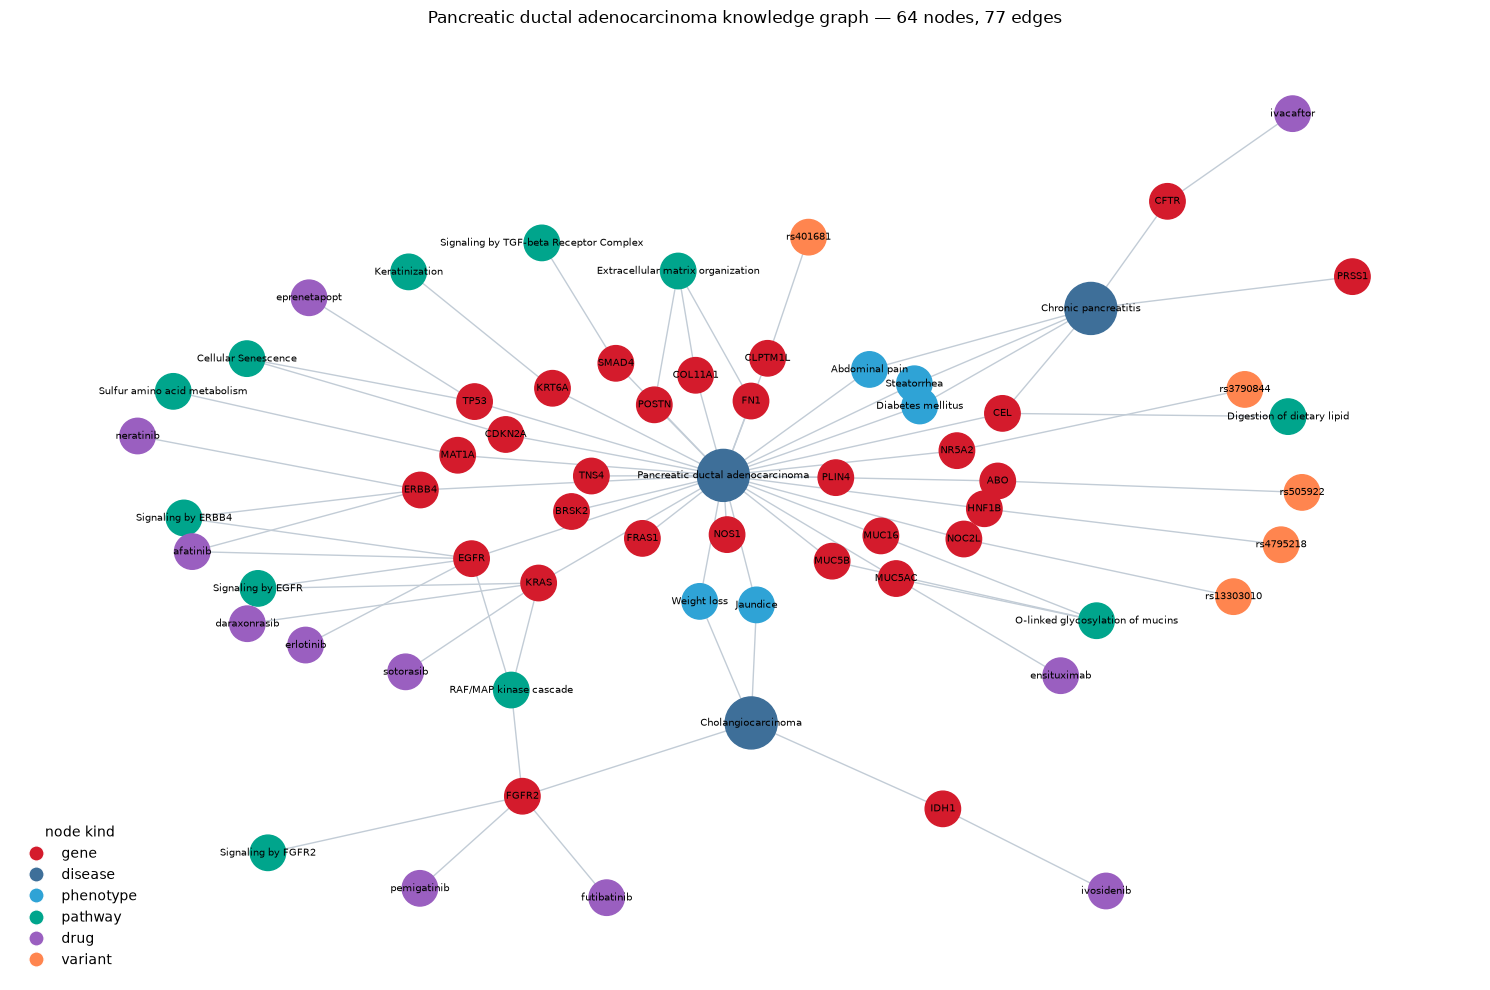

saved my_knowledge_graph.png, nodes.csv, edges.csv, biomarkers_ranked.csv


In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
pos = nx.kamada_kawai_layout(H.to_undirected())   # deterministic, less tangled than spring
plt.figure(figsize=(15, 10))
nx.draw_networkx_edges(H, pos, edge_color="#C2CCD6", width=1.0, arrows=False)
nx.draw_networkx_nodes(H, pos, node_size=[1400 if H.nodes[n]["kind"]=="disease" else 650 for n in H],
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H.nodes()])
nx.draw_networkx_labels(H, pos, font_size=7)
plt.legend(handles=[Line2D([0],[0], marker="o", color="w", markerfacecolor=c, markersize=11, label=k)
                    for k, c in KIND_COLOR.items() if k != "patient"],
           loc="lower left", frameon=False, title="node kind")
plt.axis("off")
plt.title(f"{DISEASE} knowledge graph — {H.number_of_nodes()} nodes, {H.number_of_edges()} edges")
plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv, biomarkers_ranked.csv")

## 8 · Report

The interpretation (Part F) is in `PDAC_Module7_Report.pdf`.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```